# Budget Optimisation (Part 03 – Member 2)

## Objective
Find the allocation of a **fixed monthly advertising budget** across six channels that **maximises the trained MMM's predicted sales revenue**.

**Important:** the model predicts sales; it does not prove causal ROI. Results are model-based scenarios, not guaranteed outcomes (see Limitations).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]      # notebooks/03_roi_optimization -> project root
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

from src.predict_sales import SPEND_CHANNELS, predict_budget_allocation
from src import budget_optimizer as bo

OUT = ROOT / 'outputs' / 'optimization'
OUT.mkdir(parents=True, exist_ok=True)
LABELS = {c: c.replace('_spend_lkr','').replace('_',' ').title() for c in SPEND_CHANNELS}

## 1. Load model, data and Member 1 results
- `models/mmm_model.joblib` – trained model (saturated Ridge regression)
- `data/processed/cleaned_data.csv` – historical spend, used for realistic limits
- `outputs/optimization/channel_effectiveness.csv` – Member 1's channel response analysis

In [2]:
bundle, hist, controls, prev_adstock = bo.load_inputs()
m1 = pd.read_csv(OUT / 'channel_effectiveness.csv')
print('Model:', bundle['model_name'])
print('Historical months:', len(hist))
m1[['Channel','Predicted_Sales_Change_LKR','Response_Efficiency','Performance_Rank']]

Model: saturated_ridge_regression
Historical months: 36


,Channel,Predicted_Sales_Change_LKR,Response_Efficiency,Performance_Rank
0,google_search_spend_lkr,536925.104455,1.619505,1
1,youtube_spend_lkr,302869.803956,1.364385,2
2,facebook_instagram_spend_lkr,193995.672613,0.441056,3
3,tv_spend_lkr,188777.213737,0.432964,4
4,outdoor_spend_lkr,93914.059722,0.359450,5
5,radio_spend_lkr,-41426.744080,-0.248114,6


## 2. Test the existing `predict_budget_allocation()` function
Before optimising, check that the function works, is deterministic, and responds sensibly:
equal split, negative-spend rejection, and the effect of more spend.

In [3]:
ref = bo.reference_allocation(hist)
equal = {c: ref.sum()/6 for c in SPEND_CHANNELS}

s_ref   = bo.predicted_sales(ref, controls, prev_adstock)
s_ref2  = bo.predicted_sales(ref, controls, prev_adstock)
s_equal = bo.predicted_sales(equal, controls, prev_adstock)
print(f'Reference allocation : LKR {s_ref:,.0f}')
print(f'Same input again     : LKR {s_ref2:,.0f}  (deterministic: {s_ref == s_ref2})')
print(f'Equal split          : LKR {s_equal:,.0f}')

bad = dict(ref); bad['tv_spend_lkr'] = -1
try:
    bo.predicted_sales(bad, controls, prev_adstock)
except ValueError as e:
    print('Negative spend correctly rejected ->', e)

Reference allocation : LKR 96,065,072
Same input again     : LKR 96,065,072  (deterministic: True)
Equal split          : LKR 95,404,567
Negative spend correctly rejected -> Advertising spend and previous adstock cannot be negative


## 3. Define the optimisation problem

**Decision variables:** monthly spend $x_i$ (LKR) for TV, Facebook/Instagram, Google Search, YouTube, Radio, Outdoor.

**Objective function:** maximise predicted sales $f(x)$, where $f$ = trained MMM (adstock + Hill saturation + Ridge).
SciPy minimises, so we minimise $-f(x)$.

**Constraints**
1. Fixed budget: $\sum_i x_i = B$
2. No negative budgets: $x_i \ge 0$
3. Realistic limits: $\text{min}_i \le x_i \le \text{max}_i$, using each channel's **historical min and max** monthly spend (stops extrapolating beyond observed data).

**Algorithm:** `scipy.optimize.minimize(method='SLSQP')`. The response curve is S-shaped, so the problem is non-convex; the optimiser is therefore run from several starting points and the best feasible result is kept. Variables are scaled to LKR millions for numerical stability.

**Reference ("current") allocation:** average historical monthly spend per channel. **Fixed budget B:** the total of that allocation.

**Assumptions:** external factors (price, promotion, season, etc.) and previous-month adstock are held at the December 2025 snapshot stored in the model bundle. This is a peak-season month, so predicted sales are not typical-month forecasts.

In [4]:
lower, upper = bo.spending_limits(hist)
budget = ref.sum()
pd.DataFrame({'min': lower, 'reference': ref, 'max': upper}).rename(index=LABELS).round(0)

,min,reference,max
Tv,2638465.0,4360118.0,6020432.0
Facebook Instagram,3067341.0,4398434.0,6030031.0
Google Search,2162014.0,3315365.0,5096864.0
Youtube,1476724.0,2219826.0,3178264.0
Radio,1217450.0,1669667.0,2169012.0
Outdoor,1727984.0,2612717.0,3690845.0


In [5]:
print(f'Fixed monthly budget: LKR {budget:,.0f}')

Fixed monthly budget: LKR 18,576,126


## 4. Run the SLSQP optimisation

In [6]:
opt, opt_sales, res = bo.optimise_budget(budget, lower, upper, controls, prev_adstock, start=ref.values)
print('SLSQP success:', res.success, '|', res.message)

# constraint checks
print('Budget difference (opt - fixed):', round(opt.sum() - budget, 4))
print('All >= 0:', bool((opt >= 0).all()))
print('Within limits:', bool(((opt >= lower - 1) & (opt <= upper + 1)).all()))

SLSQP success: True | Optimization terminated successfully
Budget difference (opt - fixed): 0.0
All >= 0: True
Within limits: True


## 5. Compare reference vs optimised budget

In [7]:
alloc_tbl, pred_tbl = bo.compare(ref, opt, lower, upper, controls, prev_adstock)
alloc_tbl['channel'] = alloc_tbl['channel'].map(LABELS)
display(alloc_tbl.round(1))
display(pred_tbl.round(2))

alloc_tbl.to_csv(OUT / 'optimized_budget.csv', index=False)
pred_tbl.to_csv(OUT / 'prediction_results.csv', index=False)

,channel,min_limit_lkr,max_limit_lkr,reference_budget_lkr,optimized_budget_lkr,change_lkr,change_pct,optimized_share_pct
0,Tv,2638465.0,6020432.0,4360117.8,3357071.3,-1003046.6,-23.0,18.1
1,Facebook Instagram,3067341.0,6030031.0,4398433.8,3998492.4,-399941.4,-9.1,21.5
2,Google Search,2162014.0,5096864.0,3315364.9,5096864.0,1781499.1,53.7,27.4
3,Youtube,1476724.0,3178264.0,2219825.8,3178264.0,958438.2,43.2,17.1
4,Radio,1217450.0,2169012.0,1669666.6,1217450.0,-452216.6,-27.1,6.6
5,Outdoor,1727984.0,3690845.0,2612716.7,1727984.0,-884732.7,-33.9,9.3


,total_budget_lkr,reference_predicted_sales_lkr,optimized_predicted_sales_lkr,sales_difference_lkr,improvement_pct
0,18576125.67,96065072.19,98784045.61,2718973.42,2.83


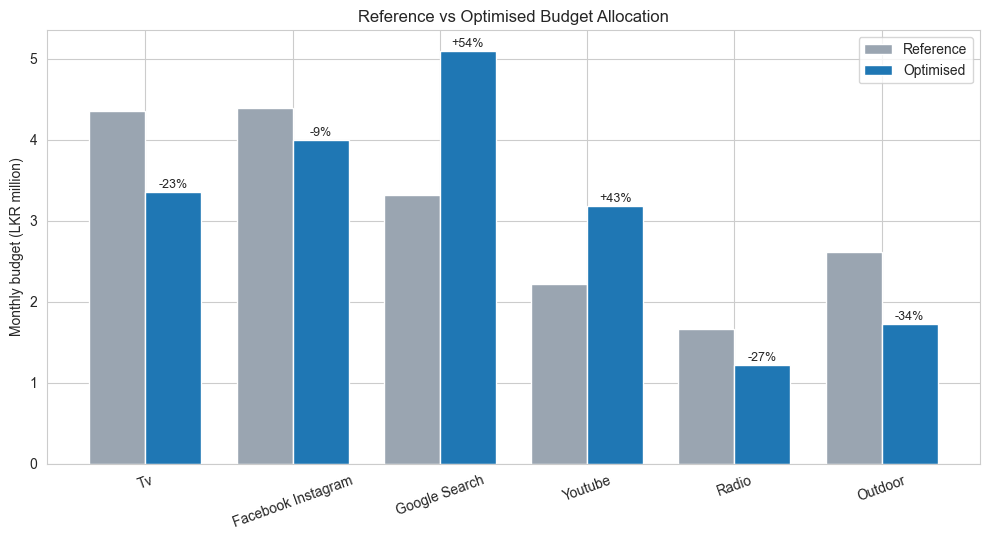

In [8]:
x = np.arange(len(alloc_tbl)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(x - w/2, alloc_tbl.reference_budget_lkr/1e6, w, label='Reference', color='#9AA5B1')
ax.bar(x + w/2, alloc_tbl.optimized_budget_lkr/1e6, w, label='Optimised', color='#1F77B4')
ax.set_xticks(x); ax.set_xticklabels(alloc_tbl.channel, rotation=20)
ax.set_ylabel('Monthly budget (LKR million)'); ax.set_title('Reference vs Optimised Budget Allocation')
ax.legend()
for i, r in alloc_tbl.iterrows():
    ax.text(i + w/2, r.optimized_budget_lkr/1e6 + 0.05, f'{r.change_pct:+.0f}%', ha='center', fontsize=9)
plt.tight_layout(); plt.savefig(OUT / 'budget_comparison.png', dpi=150); plt.show()

**Reading the chart:** budget moves toward channels with stronger estimated response (Google Search, YouTube, up to their historical maximum) and away from weaker ones (Radio, Outdoor, down to their historical minimum). This agrees with Member 1's response ranking.

## 6. Predicted sales improvement

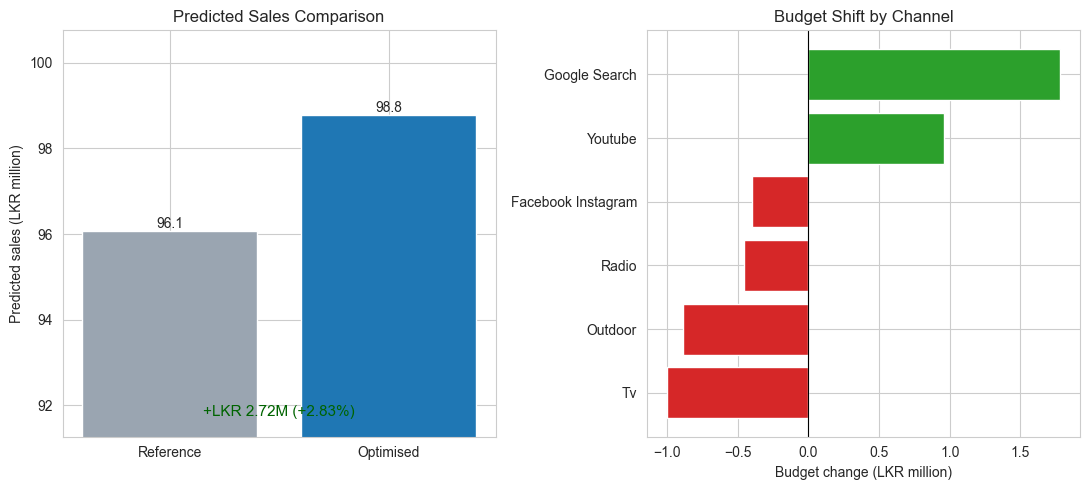

In [9]:
r = pred_tbl.iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
vals = [r.reference_predicted_sales_lkr/1e6, r.optimized_predicted_sales_lkr/1e6]
axes[0].bar(['Reference','Optimised'], vals, color=['#9AA5B1','#1F77B4'])
axes[0].set_ylim(min(vals)*0.95, max(vals)*1.02)
axes[0].set_ylabel('Predicted sales (LKR million)'); axes[0].set_title('Predicted Sales Comparison')
for i, v in enumerate(vals): axes[0].text(i, v, f'{v:,.1f}', ha='center', va='bottom')
axes[0].text(0.5, 0.05, f'+LKR {r.sales_difference_lkr/1e6:.2f}M ({r.improvement_pct:+.2f}%)',
             transform=axes[0].transAxes, ha='center', fontsize=11, color='darkgreen')

ch = alloc_tbl.sort_values('change_lkr')
axes[1].barh(ch.channel, ch.change_lkr/1e6, color=np.where(ch.change_lkr > 0, '#2CA02C', '#D62728'))
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_xlabel('Budget change (LKR million)'); axes[1].set_title('Budget Shift by Channel')
plt.tight_layout(); plt.savefig(OUT / 'sales_improvement.png', dpi=150); plt.show()

## 7. Multiple budget scenarios
Re-run the optimisation for 80%–120% of the base budget. Reference for each scenario = the reference mix scaled to that budget.

In [10]:
scen = bo.run_scenarios(ref, lower, upper, controls, prev_adstock)
scen.to_csv(OUT / 'budget_scenarios.csv', index=False)
scen[['budget_multiplier','total_budget_lkr','reference_predicted_sales_lkr',
      'optimized_predicted_sales_lkr','sales_difference_lkr','improvement_pct']].round(2)

,budget_multiplier,total_budget_lkr,reference_predicted_sales_lkr,optimized_predicted_sales_lkr,sales_difference_lkr,improvement_pct
0,0.8,14860900.53,93230897.46,9.536659e+07,2135696.41,2.29
1,0.9,16718513.10,94697571.45,9.770019e+07,3002617.55,3.17
2,1.0,18576125.67,96065072.19,9.878405e+07,2718973.42,2.83
3,1.1,20433738.23,97340127.30,9.964228e+07,2302153.50,2.37
4,1.2,22291350.80,98529429.75,1.004206e+08,1891185.47,1.92


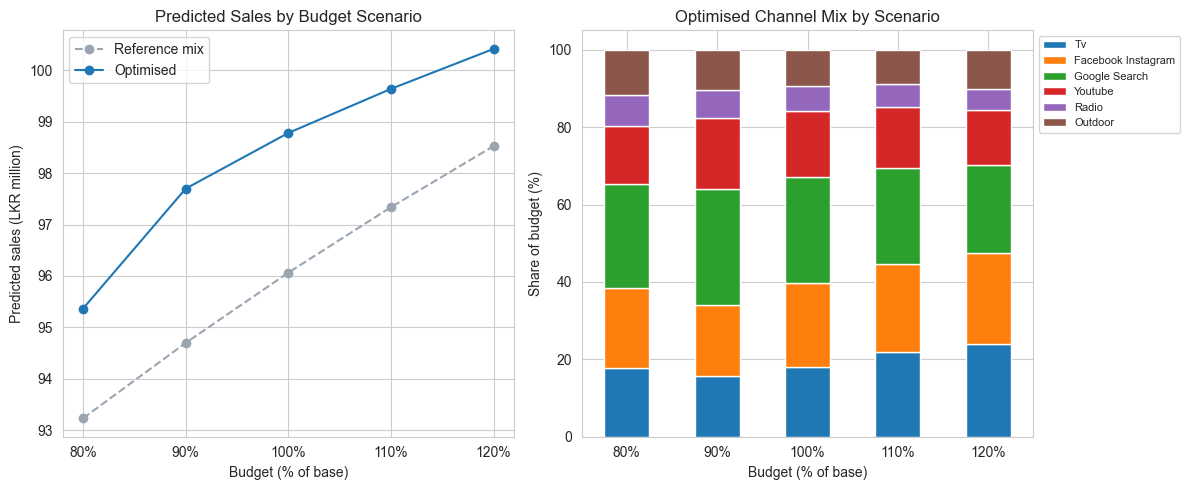

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
lab = [f'{int(m*100)}%' for m in scen.budget_multiplier]
axes[0].plot(lab, scen.reference_predicted_sales_lkr/1e6, 'o--', label='Reference mix', color='#9AA5B1')
axes[0].plot(lab, scen.optimized_predicted_sales_lkr/1e6, 'o-', label='Optimised', color='#1F77B4')
axes[0].set_xlabel('Budget (% of base)'); axes[0].set_ylabel('Predicted sales (LKR million)')
axes[0].set_title('Predicted Sales by Budget Scenario'); axes[0].legend()

cols = [f'opt_{c}' for c in SPEND_CHANNELS]
(scen[cols].div(scen[cols].sum(axis=1), axis=0)*100).set_axis(lab).rename(
    columns={f'opt_{c}': LABELS[c] for c in SPEND_CHANNELS}).plot(kind='bar', stacked=True, ax=axes[1], rot=0)
axes[1].set_ylabel('Share of budget (%)'); axes[1].set_xlabel('Budget (% of base)')
axes[1].set_title('Optimised Channel Mix by Scenario'); axes[1].legend(fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.savefig(OUT / 'budget_scenarios.png', dpi=150); plt.show()

## 8. Testing the algorithm

In [12]:
# Test 1: optimiser beats random feasible allocations
rng = np.random.default_rng(0); best_rand = -np.inf
for _ in range(2000):
    x = rng.uniform(lower.values, upper.values); x = np.clip(x*budget/x.sum(), lower.values, upper.values)
    if abs(x.sum()-budget) < 1:
        best_rand = max(best_rand, bo.predicted_sales(dict(zip(SPEND_CHANNELS, x)), controls, prev_adstock))
print(f'Best of random feasible allocations: LKR {best_rand:,.0f}')
print(f'SLSQP optimum                      : LKR {opt_sales:,.0f}')
print('Optimiser >= random search:', opt_sales >= best_rand)

# Test 2: different starting points reach a similar optimum
for seed in (1, 2, 3):
    _, s, _ = bo.optimise_budget(budget, lower, upper, controls, prev_adstock, seed=seed)
    print(f'seed {seed}: LKR {s:,.0f}')

# Test 3: infeasible budget is rejected
try:
    bo.optimise_budget(1e6, lower, upper, controls, prev_adstock)
except ValueError as e:
    print('Infeasible budget rejected ->', e)

Best of random feasible allocations: LKR 98,486,524
SLSQP optimum                      : LKR 98,784,046
Optimiser >= random search: True
seed 1: LKR 98,784,046
seed 2: LKR 98,784,046
seed 3: LKR 98,784,046
Infeasible budget rejected -> Budget infeasible for the given channel limits


## 9. Findings
- The optimised mix raises **predicted** monthly sales over the reference mix at the same total budget (see Section 5 for exact LKR and % figures).
- Budget shifts toward **Google Search and YouTube** and away from **Radio and Outdoor** (and some from TV), matching Member 1's response ranking.
- Channels end at their historical min/max limits, so the result is limit-driven. Different limits would give a different answer.
- Gains by scenario are shown in `budget_scenarios.csv`.

## 10. Limitations
1. **Prediction, not causal ROI.** The model is observational; moving budget may not give these gains.
2. **Small data:** only 36 monthly rows; rolling backtest accuracy (R² ≈ 0.59) is much weaker than the holdout R² (0.93).
3. **Adstock decay rates are assumptions** (not estimated); Hill slope is fixed.
4. **Radio's negative effect** in the model is counterintuitive and likely a collinearity artefact; the optimiser cuts Radio partly because of it.
5. **Single-month, fixed-snapshot optimisation:** external factors and prior adstock are held at the December 2025 peak-season values.
6. **Limits stay inside observed spend ranges** to avoid extrapolation; the result depends on those limits.
7. **Non-convex objective:** SLSQP finds a local optimum; multiple starts reduce but do not remove this risk.